# Construction Safety — Seven Movement Analyses

**Source:** local VTT-ConIoT CSVs in this project. These are movement measurements and exploratory features, **not validated fatigue/stress or injury diagnoses**. All graphs export PNG and interactive HTML (where possible), plus analysis tables as CSV.

Run cells in order. Graph 1 uses **actual model reconstruction scores only if you supply a compatible scored CSV**; it never substitutes motion intensity for autoencoder error. Graph 6 requires a verified matching IMU/keypoint pair and does not claim synchronized timing without metadata. Graph 7 compares task movement profiles, not task safety or worker fitness.

## 0. Setup and locate files

In [1]:
# Install once in VS Code terminal:
# python -m pip install pandas numpy matplotlib seaborn scikit-learn plotly kaleido ipykernel
from pathlib import Path
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
# Supports notebook in project root or a notebooks/ subfolder
for parent in [ROOT, *ROOT.parents]:
    if (parent/'data').exists() or (parent/'File conversions').exists():
        ROOT = parent; break
SEARCH_DIRS = [ROOT/'data', ROOT/'File conversions'/'VTT_ConIot_Dataset', ROOT/'VTT_ConIot_Dataset']
CSV_FILES = sorted(set(p.resolve() for folder in SEARCH_DIRS if folder.exists() for p in folder.rglob('*.csv')))
OUT = ROOT/'reports'/'safety_analysis'; OUT.mkdir(parents=True,exist_ok=True)
print('Project:',ROOT,'\nCSV files:',len(CSV_FILES),'\nExports:',OUT)
if not CSV_FILES: raise FileNotFoundError('No CSVs found. Set SEARCH_DIRS to your extracted VTT dataset folder.')

def read(path): return pd.read_csv(path,low_memory=False)
def is_pose(path): return 'keypoint' in path.name.lower()
POSE_FILES = [p for p in CSV_FILES if is_pose(p)]
IMU_FILES = [p for p in CSV_FILES if not is_pose(p)]
print('Pose:',len(POSE_FILES),'IMU candidates:',len(IMU_FILES))
print('First IMU:',IMU_FILES[0].name if IMU_FILES else 'none')
if IMU_FILES: print('Columns:',read(IMU_FILES[0]).columns.tolist()[:45])

def savefig(name):
    plt.tight_layout(); plt.savefig(OUT/f'{name}.png',dpi=170,bbox_inches='tight'); plt.show()

def csvsave(df,name):
    df.to_csv(OUT/f'{name}.csv',index=False)

def subject(path):
    s=path.stem.lower()
    m=re.search(r'(?:subject|subj|participant|person|worker)[_\- ]*0*(\d+)',s)
    return m.group(1) if m else None

def activity(path):
    s=path.stem.lower()
    m=re.search(r'(?:activity|task)[_\- ]*0*(\d+)',s)
    return 'task_'+m.group(1) if m else path.stem[:45]


Project: c:\Users\sanja\Hackaton_Group3_AIMethods 
CSV files: 401 
Exports: c:\Users\sanja\Hackaton_Group3_AIMethods\reports\safety_analysis
Pose: 194 IMU candidates: 207
First IMU: activity_10_user_10_combined.csv
Columns: ['datetime', 'trousers_index', 'trousers_Gx_dps', 'trousers_Gy_dps', 'trousers_Gz_dps', 'trousers_Ax_g', 'trousers_Ay_g', 'trousers_Az_g', 'trousers_ts', 'trousers_Mx_uT', 'trousers_My_uT', 'trousers_Mz_uT', 'trousers_mbar', 'trousers_tot_g', 'trousers_tot_dps', 'back_index', 'back_Gx_dps', 'back_Gy_dps', 'back_Gz_dps', 'back_Ax_g', 'back_Ay_g', 'back_Az_g', 'back_ts', 'back_Mx_uT', 'back_My_uT', 'back_Mz_uT', 'back_mbar', 'back_tot_g', 'back_tot_dps', 'hand_index', 'hand_Gx_dps', 'hand_Gy_dps', 'hand_Gz_dps', 'hand_Ax_g', 'hand_Ay_g', 'hand_Az_g', 'hand_ts', 'hand_Mx_uT', 'hand_My_uT', 'hand_Mz_uT', 'hand_mbar', 'hand_tot_g', 'hand_tot_dps']


## 1. Activity-wise autoencoder reconstruction error
Supply an exported scored CSV with **activity** and **reconstruction_error** columns (optionally **subject**). This cell does not calculate or fabricate model errors.

In [2]:
# Export from your trained model pipeline: one row per evaluated window.
# Example columns: activity, reconstruction_error, subject
SCORES_CSV = ROOT/'reports'/'autoencoder_window_scores.csv'
if SCORES_CSV.exists():
    scores=pd.read_csv(SCORES_CSV)
    required={'activity','reconstruction_error'}
    if not required.issubset(scores.columns):
        print('Expected columns:',required,'Found:',list(scores.columns))
    else:
        scores['reconstruction_error']=pd.to_numeric(scores['reconstruction_error'],errors='coerce')
        scores=scores.dropna(subset=['activity','reconstruction_error'])
        order=scores.groupby('activity')['reconstruction_error'].median().sort_values().index
        plt.figure(figsize=(12,5)); sns.boxplot(data=scores,x='activity',y='reconstruction_error',order=order,showfliers=False)
        plt.xticks(rotation=60,ha='right'); plt.title('Actual autoencoder reconstruction error by activity (not fatigue)')
        savefig('01_reconstruction_error_by_activity')
        csvsave(scores.groupby('activity',as_index=False).agg(n=('reconstruction_error','size'),median_error=('reconstruction_error','median'),mean_error=('reconstruction_error','mean')),'01_activity_error_summary')
else:
    print('Graph 1 awaiting model output:',SCORES_CSV)
    print('Export evaluated windows from your autoencoder with columns: activity, reconstruction_error, subject (optional).')


Graph 1 awaiting model output: c:\Users\sanja\Hackaton_Group3_AIMethods\reports\autoencoder_window_scores.csv
Export evaluated windows from your autoencoder with columns: activity, reconstruction_error, subject (optional).


## Shared IMU features
Features use sensor magnitude variability and gyroscope magnitude. Units remain separate. The values are **movement descriptors**, not fatigue scores. The file-derived task/subject parsing is provisional; inspect labels before using them for assignment.

In [3]:
REGIONS=['hand','back','trousers']
def findcols(df,region,kind):
    if kind=='acc': suffix=['Ax_g','Ay_g','Az_g']
    else: suffix=['Gx_dps','Gy_dps','Gz_dps']
    cols=[f'{region}_{x}' for x in suffix]
    return cols if all(c in df for c in cols) else []

def magnitude(df,region,kind):
    cols=findcols(df,region,kind)
    if not cols: return None
    a=df[cols].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=float)
    return np.sqrt(np.nansum(a*a,axis=1))

def file_features(path):
    df=read(path); row={'file':str(path),'activity':activity(path),'subject':subject(path),'samples':len(df)}
    found=False
    for r in REGIONS:
        acc=magnitude(df,r,'acc'); gyr=magnitude(df,r,'gyro')
        if acc is not None:
            row[f'{r}_acc_std_g']=float(np.nanstd(acc)); found=True
        if gyr is not None:
            row[f'{r}_gyro_mean_dps']=float(np.nanmean(gyr)); found=True
            row[f'{r}_gyro_std_dps']=float(np.nanstd(gyr))
    return row if found else None

records=[]
for i,p in enumerate(IMU_FILES):
    try:
        f=file_features(p)
        if f: records.append(f)
    except Exception as e: print('Skipped:',p.name,str(e)[:100])
features=pd.DataFrame(records)
if features.empty: raise ValueError('No recognized IMU channels. Inspect the printed column names and update findcols().')
display(features.head())
csvsave(features,'imu_recording_features')
print('Recognized IMU recordings:',len(features),'with subject IDs:',features.subject.notna().sum())


,file,activity,subject,samples,hand_acc_std_g,hand_gyro_mean_dps,hand_gyro_std_dps,back_acc_std_g,back_gyro_mean_dps,back_gyro_std_dps,trousers_acc_std_g,trousers_gyro_mean_dps,trousers_gyro_std_dps
0,C:\Users\sanja\Hackaton_Group3_AIMethods\data\...,task_10,None,5999,0.260229,37.914013,25.253023,0.263852,20.514770,15.948487,0.205316,12.746254,14.153440
1,C:\Users\sanja\Hackaton_Group3_AIMethods\data\...,task_10,None,5998,0.260774,52.739563,41.252646,0.257829,25.940917,22.240105,0.210384,9.282920,14.436880
2,C:\Users\sanja\Hackaton_Group3_AIMethods\data\...,task_10,None,6000,0.272403,26.344208,25.910844,0.267342,12.921850,17.319984,0.220454,10.345000,19.861681
3,C:\Users\sanja\Hackaton_Group3_AIMethods\data\...,task_10,None,5999,0.236194,19.524273,17.247829,0.262709,14.964056,16.021298,0.212933,12.539446,12.724417
4,C:\Users\sanja\Hackaton_Group3_AIMethods\data\...,task_10,None,5999,0.208918,28.293327,27.694846,0.265819,18.458796,21.936865,0.242994,15.241379,18.974647


Recognized IMU recordings: 207 with subject IDs: 0


## 2. Body-region movement heatmap
Separate heatmaps for acceleration variability (g) and mean gyroscope magnitude (degrees/s), to avoid mixing units.

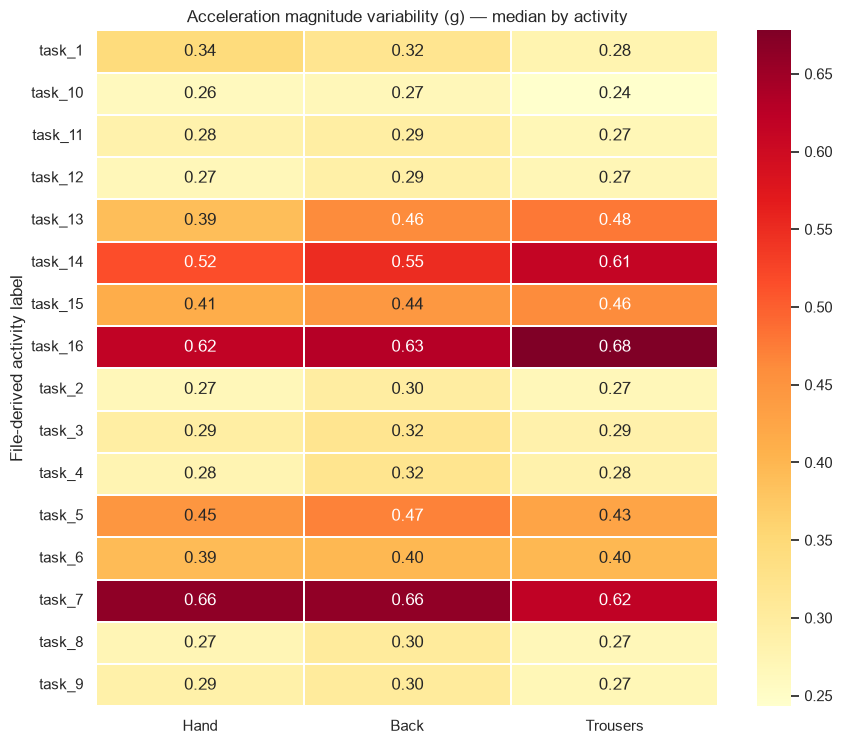

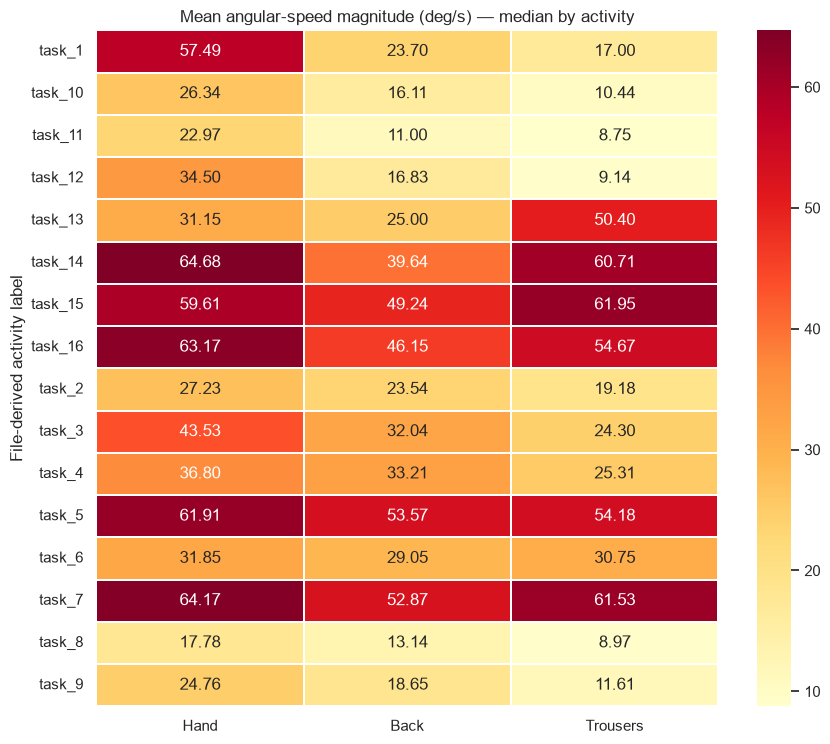

In [4]:
for metric,title in [('acc_std_g','Acceleration magnitude variability (g)'),('gyro_mean_dps','Mean angular-speed magnitude (deg/s)')]:
    cols=[f'{r}_{metric}' for r in REGIONS]
    available=[c for c in cols if c in features]
    if not available: continue
    matrix=features.groupby('activity')[available].median()
    matrix.columns=[c.split('_')[0].title() for c in available]
    plt.figure(figsize=(9,max(4,0.35*len(matrix)+2)))
    sns.heatmap(matrix,annot=len(matrix)<=20,fmt='.2f',cmap='YlOrRd',linewidths=.3)
    plt.title(title+' — median by activity'); plt.ylabel('File-derived activity label')
    savefig('02_heatmap_'+metric)
    matrix.to_csv(OUT/f'02_heatmap_{metric}.csv')


## 3. Cumulative movement exposure within one recording
Shows cumulative **angular displacement proxy** from gyroscope magnitude (degrees), assuming a known sample rate. Set the actual sample rate; without it the chart is in sample-based units and cannot be interpreted as duration.

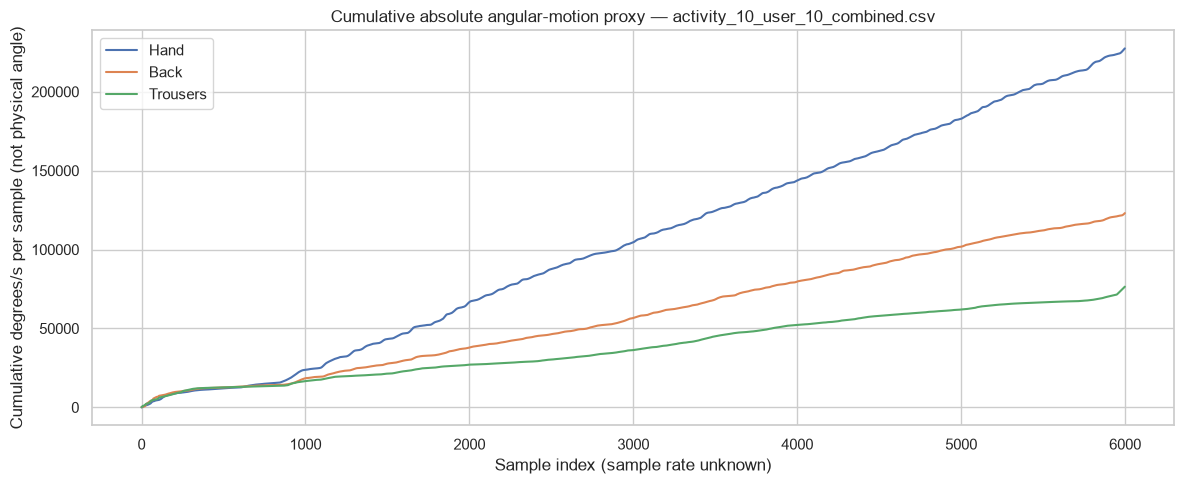

Note: gyroscope magnitude integral is a motion-exposure proxy, not joint angle or tissue loading.


In [5]:
SELECT_IMU = Path(features.iloc[0]['file'])
SAMPLE_RATE_HZ = None  # Set verified rate, e.g. 100, only if documented for this recording
imu=read(SELECT_IMU)
plt.figure(figsize=(12,5)); rows=[]
for r in REGIONS:
    g=magnitude(imu,r,'gyro')
    if g is None: continue
    g=np.nan_to_num(g,nan=0.0)
    cumulative=np.cumsum(g/(SAMPLE_RATE_HZ if SAMPLE_RATE_HZ else 1.0))
    plt.plot(np.arange(len(g))/(SAMPLE_RATE_HZ if SAMPLE_RATE_HZ else 1.0),cumulative,label=r.title())
    rows.append(pd.DataFrame({'sample':np.arange(len(g)),'region':r,'cumulative':cumulative}))
plt.title('Cumulative absolute angular-motion proxy — '+SELECT_IMU.name)
plt.xlabel('Time (s)' if SAMPLE_RATE_HZ else 'Sample index (sample rate unknown)')
plt.ylabel('Integrated angular-speed magnitude (degrees)' if SAMPLE_RATE_HZ else 'Cumulative degrees/s per sample (not physical angle)')
plt.legend(); savefig('03_cumulative_motion')
if rows: csvsave(pd.concat(rows,ignore_index=True),'03_cumulative_motion')
print('Note: gyroscope magnitude integral is a motion-exposure proxy, not joint angle or tissue loading.')


## 4. Worker-specific baseline comparison
Compare each worker to their own median across **other recordings of the same activity**. If repeated labeled recordings are unavailable, do not claim a worker-specific baseline.

In [6]:
metric='back_gyro_mean_dps'
if metric in features:
    valid=features.dropna(subset=['subject',metric]).copy()
    counts=valid.groupby(['subject','activity'])[metric].transform('size')
    valid=valid[counts>=2].copy()
    if len(valid):
        # leave-one-recording-out median baseline, avoiding comparison with itself
        def baseline(s): return s.apply(lambda v: np.nan) if len(s)<2 else pd.Series([s.drop(i).median() for i in s.index],index=s.index)
        valid['baseline']=valid.groupby(['subject','activity'])[metric].transform(baseline)
        valid['difference']=valid[metric]-valid['baseline']
        top=valid.reindex(valid['difference'].abs().sort_values(ascending=False).index).head(30)
        plt.figure(figsize=(12,5)); sns.barplot(data=top,x='file',y='difference',color='#4477AA')
        plt.xticks(rotation=90,fontsize=6);plt.title('Deviation from leave-one-out worker/task baseline (deg/s)')
        savefig('04_worker_baseline');csvsave(valid,'04_worker_baseline')
    else: print('Graph 4 unavailable: need repeated recordings per subject AND activity with parsed subject IDs.')
else: print('Missing feature:',metric)


Graph 4 unavailable: need repeated recordings per subject AND activity with parsed subject IDs.


## 5. PCA clustering of activity movement features
This is **PCA on engineered IMU features**, not autoencoder latent embeddings. To analyze actual latent space, export the encoder vectors and use those instead.

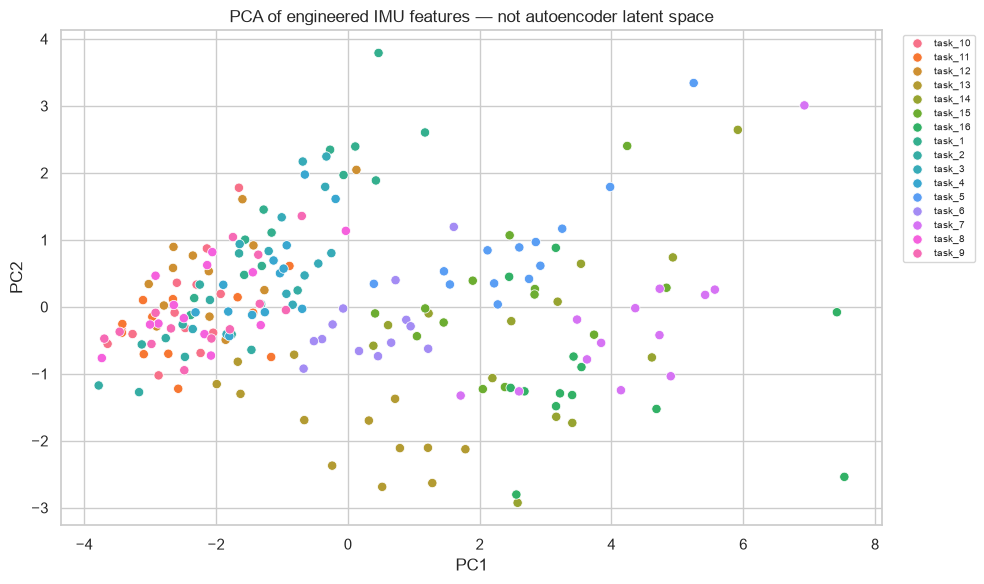

In [7]:
feature_cols=[c for c in features if c.endswith(('_acc_std_g','_gyro_mean_dps','_gyro_std_dps'))]
X=features[feature_cols].apply(pd.to_numeric,errors='coerce')
X=X.fillna(X.median()).fillna(0)
if len(X)>=3 and X.shape[1]>=2:
    Xs=StandardScaler().fit_transform(X)
    pcs=PCA(n_components=2).fit_transform(Xs)
    embedding=features[['file','activity','subject']].copy()
    embedding['PC1']=pcs[:,0];embedding['PC2']=pcs[:,1]
    plt.figure(figsize=(10,6));sns.scatterplot(data=embedding,x='PC1',y='PC2',hue='activity',s=45,legend='brief')
    plt.title('PCA of engineered IMU features — not autoencoder latent space')
    plt.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=7)
    savefig('05_pca_activity_features');csvsave(embedding,'05_pca_activity_features')
else: print('Not enough recordings/features for PCA.')


## 6. Skeleton and IMU paired visualization
Only run after manually verifying that the two recordings represent the **same session**. Without verified timestamps, the plots show separate sample indices, **not synchronized events**.

In [8]:
SELECT_POSE = POSE_FILES[0] if POSE_FILES else None
MATCH_VERIFIED = False  # Change only after checking recording IDs/metadata
if SELECT_POSE is None:
    print('No pose files found.')
elif not MATCH_VERIFIED:
    print('Graph 6 requires verified IMU + pose pairing. Selected examples:')
    print('Pose:',SELECT_POSE.name,'\nIMU:',SELECT_IMU.name)
    print('Confirm session match before setting MATCH_VERIFIED=True.')
else:
    pose=read(SELECT_POSE)
    needed=[f'{axis}{i}' for axis in ('x','y','prob') for i in (5,6,11,12)]
    if not all(c in pose for c in needed):
        print('Required pose columns missing:',set(needed)-set(pose.columns))
    else:
        x=lambda i:pd.to_numeric(pose[f'x{i}'],errors='coerce').to_numpy()
        y=lambda i:pd.to_numeric(pose[f'y{i}'],errors='coerce').to_numpy()
        p=lambda i:pd.to_numeric(pose[f'prob{i}'],errors='coerce').to_numpy()
        dx=(x(5)+x(6)-x(11)-x(12))/2
        dy=(y(5)+y(6)-y(11)-y(12))/2
        angle=np.degrees(np.arctan2(np.abs(dx),np.abs(dy)))
        confidence=np.minimum.reduce([p(i) for i in (5,6,11,12)])
        angle[confidence<0.3]=np.nan
        gyro=magnitude(imu,'back','gyro')
        fig,axes=plt.subplots(2,1,figsize=(12,7))
        axes[0].plot(np.arange(len(angle)),angle);axes[0].set_title('2D image-relative trunk inclination');axes[0].set_xlabel('Pose frame index');axes[0].set_ylabel('Degrees')
        if gyro is not None:axes[1].plot(np.arange(len(gyro)),gyro)
        axes[1].set_title('Back gyroscope magnitude — separate timebase');axes[1].set_xlabel('IMU sample index');axes[1].set_ylabel('deg/s')
        savefig('06_pose_imu_unsynchronized')
        csvsave(pd.DataFrame({'pose_frame':np.arange(len(angle)),'inclination_deg':angle}),'06_pose_angles')


Graph 6 requires verified IMU + pose pairing. Selected examples:
Pose: Subject_01_Task_1.m2ts_keyPoints.csv 
IMU: activity_10_user_10_combined.csv
Confirm session match before setting MATCH_VERIFIED=True.


## 7. Next-day task rotation comparison
This is a **task movement-profile difference matrix** computed from median sensor features. Greater difference does not imply safer work. Limitation: It cannot assign tasks to individual workers without qualifications, risk assessment and supervisor review.

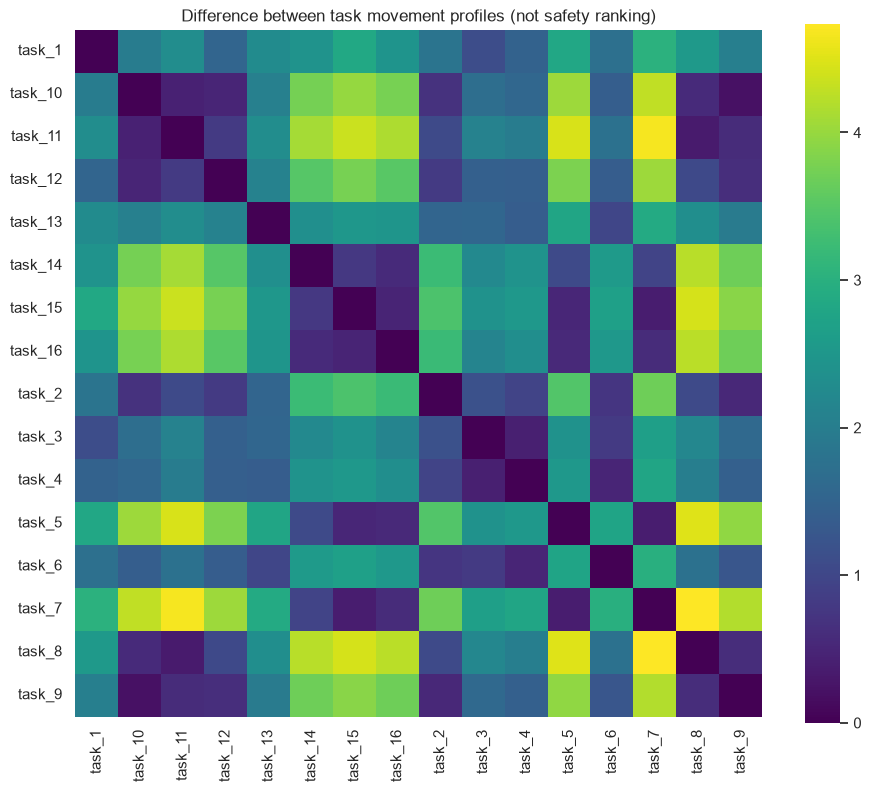

All outputs saved to: c:\Users\sanja\Hackaton_Group3_AIMethods\reports\safety_analysis


In [9]:
cols=[f'{r}_gyro_mean_dps' for r in REGIONS if f'{r}_gyro_mean_dps' in features]
profiles=features.groupby('activity')[cols].median().dropna(how='all')
if len(profiles)>=2 and cols:
    # Standardize each sensor column across tasks to compare patterns, not absolute units
    scaled=(profiles-profiles.mean())/profiles.std(ddof=0).replace(0,1)
    scaled=scaled.fillna(0)
    names=scaled.index.tolist()
    dist=np.linalg.norm(scaled.to_numpy()[:,None,:]-scaled.to_numpy()[None,:,:],axis=2)
    matrix=pd.DataFrame(dist,index=names,columns=names)
    plt.figure(figsize=(max(7,len(names)*.6),max(6,len(names)*.5)))
    sns.heatmap(matrix,cmap='viridis',square=True)
    plt.title('Difference between task movement profiles (not safety ranking)')
    savefig('07_task_profile_distance')
    matrix.to_csv(OUT/'07_task_profile_distance.csv')
    profiles.to_csv(OUT/'07_task_movement_profiles.csv')
else: print('Need at least two task labels and recognized gyroscope channels.')
print('All outputs saved to:',OUT)


## Interpretation and next integration steps

- **Graph 1:** export *held-out* model window errors with real task labels. Reconstruction error is not a fatigue label.
- **Graphs 2–3:** real movement descriptors, but no tissue-specific strain or physiological fatigue inference.
- **Graph 4:** subject/task baselines require reliable IDs and repeated comparable sessions.
- **Graph 5:** engineered-feature PCA; use exported encoder embeddings for actual latent-space analysis.
- **Graph 6:** only interpret cross-modal timing if paired session IDs and synchronization are verified.
- **Graph 7:** movement differences can suggest alternatives to *review*, not automatically assign.

For real fatigue/stress claims, collect validated ground-truth labels and evaluate generalization on unseen workers. For the app, display measured values, confidence/missingness, and experimental indicators separately.